# Task 1 — Exploratory Data Analysis (EDA)

**CodeNova AI/ML Internship — Batch 01**

This notebook uses the public Wine dataset bundled with scikit-learn. Run all cells from top to bottom. Generated charts and a profile report are saved under `outputs/`.

## 1. Imports and dataset ingestion

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
sns.set_theme(style='whitegrid')
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
bunch = load_wine(as_frame=True)
df = bunch.data.copy()
df['target'] = bunch.target
df['target_name'] = df['target'].map(dict(enumerate(bunch.target_names)))
print('Shape:', df.shape)
display(df.head())

Shape: (178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,target_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


## 2. Data quality and summary profiling

The checks below report missing values and duplicate rows before cleaning. Numeric missing values are median-imputed only if present; duplicates are removed only if present.

In [2]:
print('Data types:\n', df.dtypes)
print('\nMissing values:\n', df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
display(df.describe().T)
cleaned = df.drop_duplicates().copy()
for col in cleaned.select_dtypes(include=np.number).columns:
    if cleaned[col].isna().any():
        cleaned[col] = cleaned[col].fillna(cleaned[col].median())
print('Cleaned shape:', cleaned.shape)
print('Class counts:\n', cleaned['target_name'].value_counts())

Data types:
 alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
target_name                         str
dtype: object

Missing values:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue            

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


Cleaned shape: (178, 15)
Class counts:
 target_name
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


## 3. Missing values

A zero bar means no missing values were found in that column. If missing values exist, investigate their cause before choosing imputation or row removal.

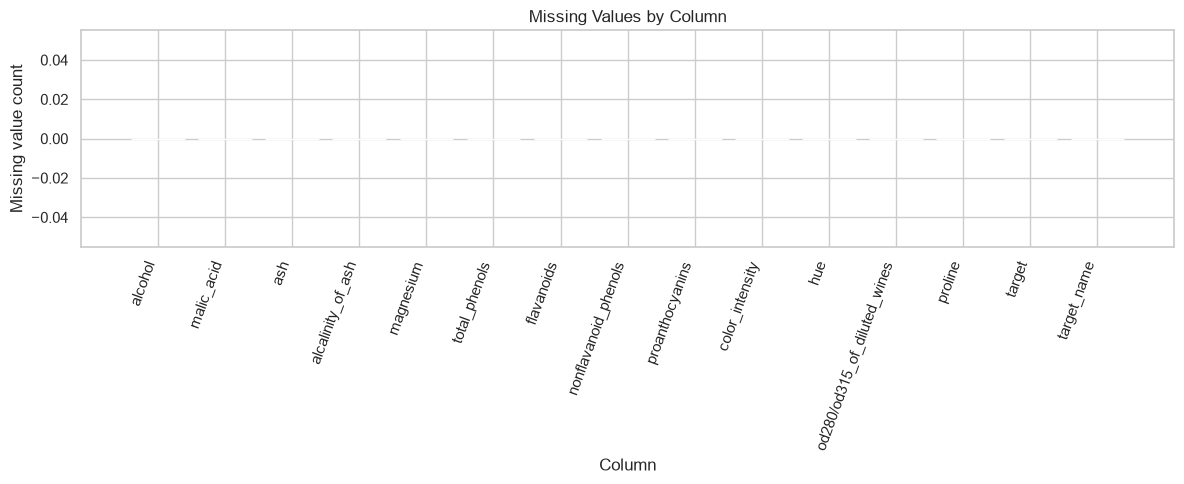

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
plt.figure(figsize=(12, 5))
plt.bar(missing.index, missing.values)
plt.title('Missing Values by Column'); plt.xlabel('Column'); plt.ylabel('Missing value count')
plt.xticks(rotation=70, ha='right'); plt.tight_layout(); plt.show()

## 4. Feature distributions

Histograms reveal skew, spread, and potential unusual values. Describe only patterns visible in the generated plots.

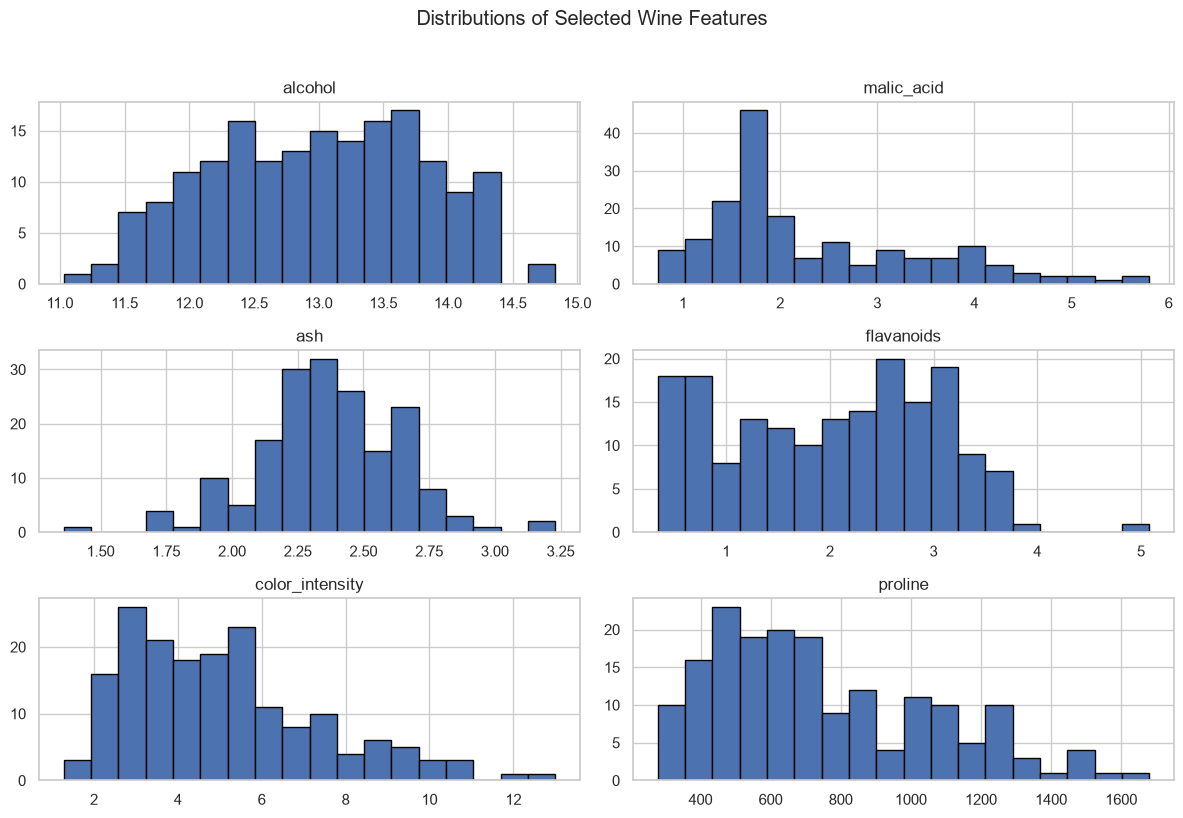

In [4]:
cols = ['alcohol', 'malic_acid', 'ash', 'flavanoids', 'color_intensity', 'proline']
cleaned[cols].hist(figsize=(12, 8), bins=18, edgecolor='black')
plt.suptitle('Distributions of Selected Wine Features', y=1.02); plt.tight_layout(); plt.show()

## 5. Correlation heatmap

Correlation measures linear association, not causation. Strongly correlated features may carry overlapping information.

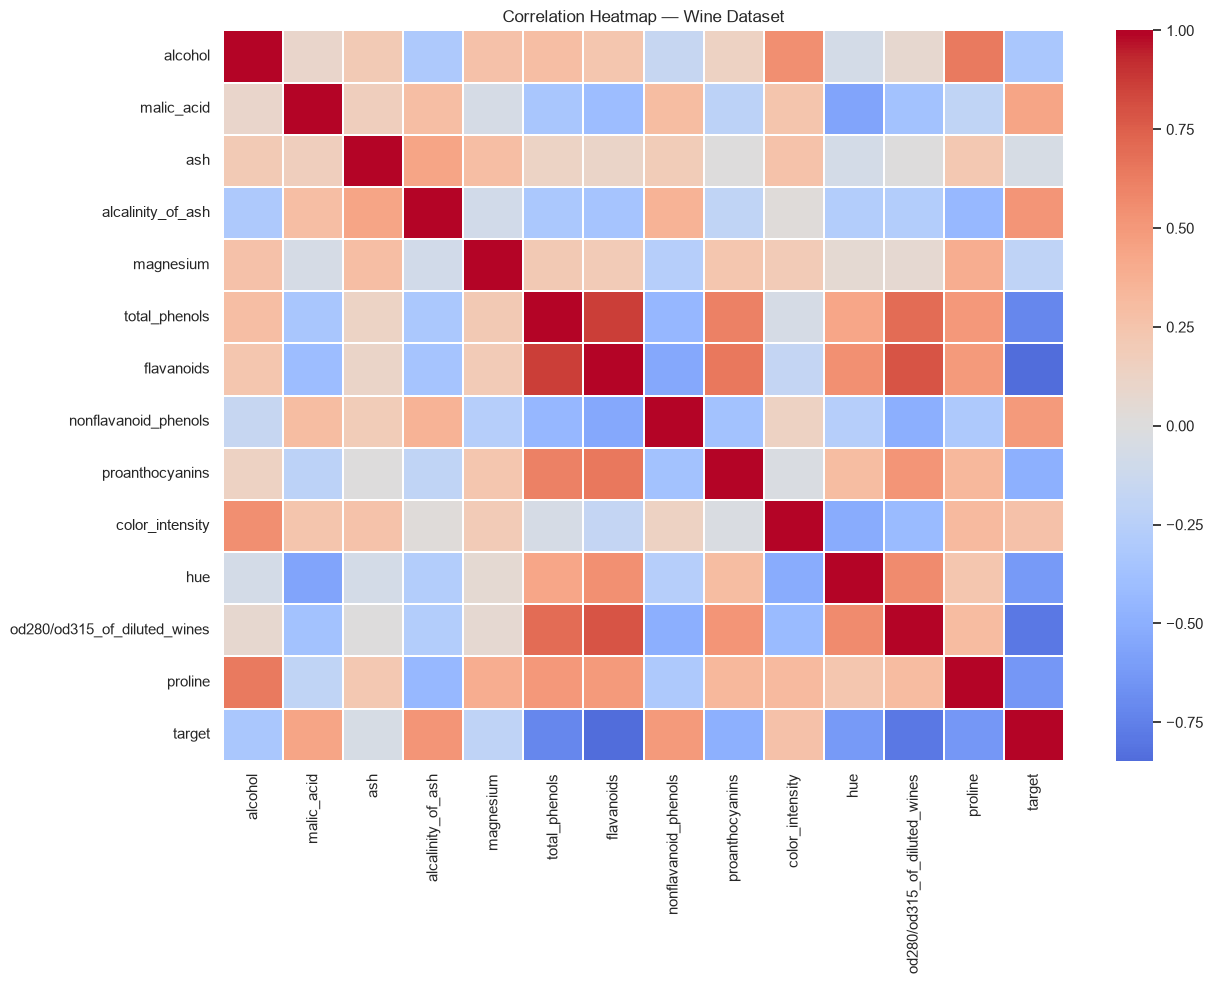

In [5]:
plt.figure(figsize=(13, 10))
sns.heatmap(cleaned.select_dtypes(include=np.number).corr(), cmap='coolwarm', center=0, linewidths=.25)
plt.title('Correlation Heatmap — Wine Dataset'); plt.tight_layout(); plt.show()

## 6. Outlier investigation with IQR

The IQR rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Flags are prompts for investigation, not proof of errors.

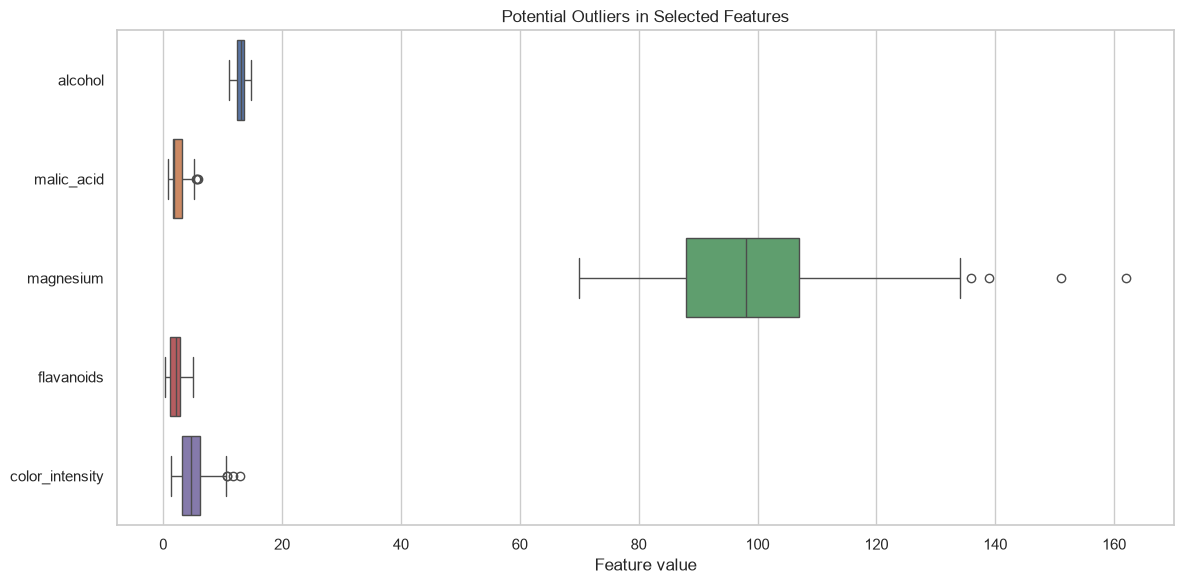

{
  "alcohol": 0,
  "malic_acid": 3,
  "ash": 3,
  "alcalinity_of_ash": 4,
  "magnesium": 4,
  "total_phenols": 0,
  "flavanoids": 0,
  "nonflavanoid_phenols": 0,
  "proanthocyanins": 2,
  "color_intensity": 4,
  "hue": 1,
  "od280/od315_of_diluted_wines": 0,
  "proline": 0
}


In [6]:
box_cols = ['alcohol', 'malic_acid', 'magnesium', 'flavanoids', 'color_intensity']
plt.figure(figsize=(12, 6)); sns.boxplot(data=cleaned[box_cols], orient='h')
plt.title('Potential Outliers in Selected Features'); plt.xlabel('Feature value'); plt.tight_layout(); plt.show()
outlier_counts = {}
for col in bunch.data.columns:
    q1, q3 = cleaned[col].quantile([.25, .75]); iqr = q3 - q1
    outlier_counts[col] = int(((cleaned[col] < q1 - 1.5*iqr) | (cleaned[col] > q3 + 1.5*iqr)).sum())
print(json.dumps(outlier_counts, indent=2))

## 7. Pairwise relationships

Use the class colours to assess whether selected feature pairs visually separate wine classes. Visual separation is descriptive, not a model-performance result.

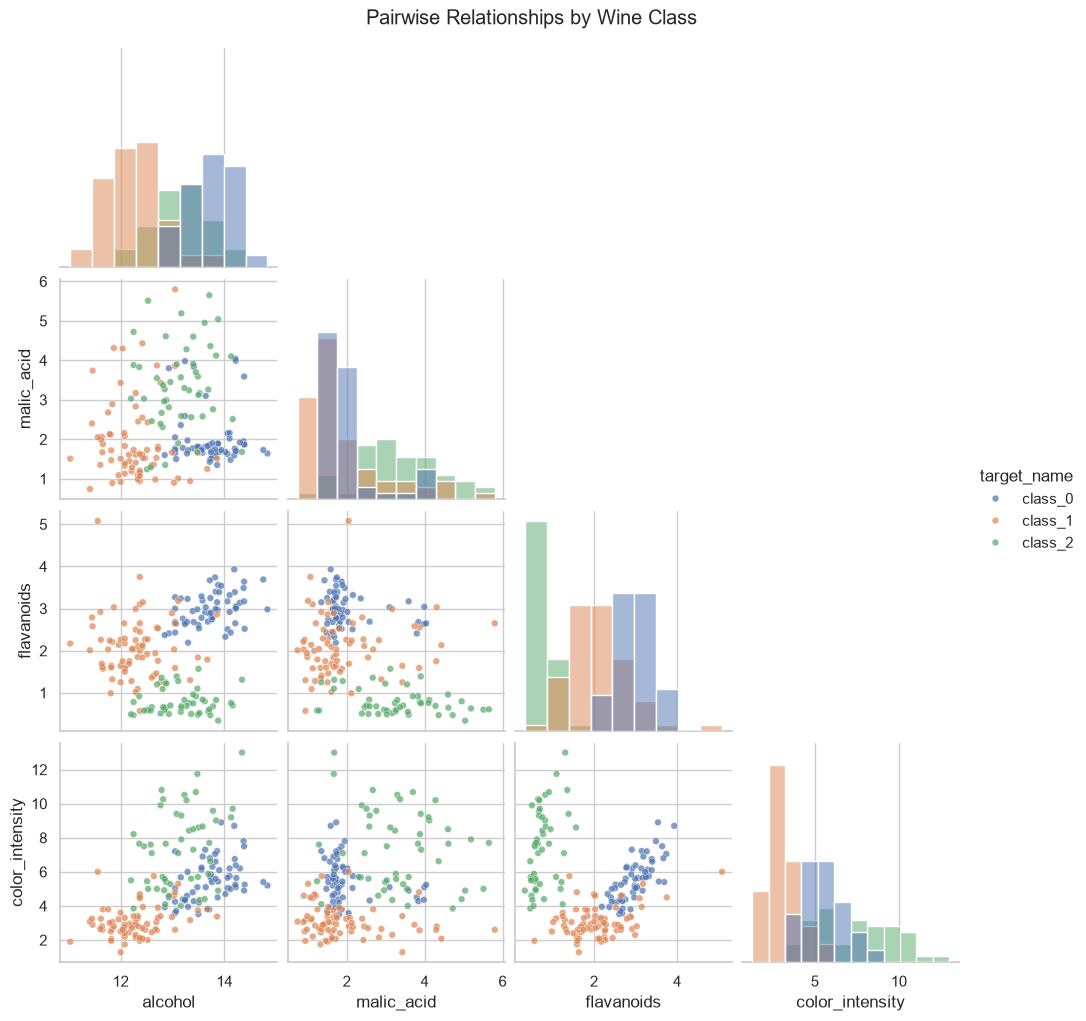

In [7]:
pair = sns.pairplot(cleaned, vars=['alcohol', 'malic_acid', 'flavanoids', 'color_intensity'], hue='target_name', corner=True, diag_kind='hist', plot_kws={'alpha': .7, 's': 24})
pair.fig.suptitle('Pairwise Relationships by Wine Class', y=1.02)
plt.show()

## 8. Conclusions (complete after reviewing outputs)

- **Data quality:** Record the observed missing-value and duplicate counts.
- **Distributions:** Identify features with broad spread or skew, based on the histograms.
- **Relationships:** Name feature pairs with strong positive or negative correlation, based on the heatmap.
- **Outliers:** Record IQR-flagged features and explain why flagged values were retained pending domain investigation.
- **Class patterns:** Describe any visible separation in pairwise plots.

Do not write conclusions until you have reviewed the executed outputs.